# Inclass 13

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
df = pd.read_csv("bank_dataset (1).csv")
df = df.drop(columns=['ID','ZIP Code'])
with pd.option_context('display.max_rows', 10): display(df)


,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,4,1.6,1,0,0,1,0,0,0
1,45,19,34,3,1.5,1,0,0,1,0,0,0
2,39,15,11,1,1.0,1,0,0,0,0,0,0
3,35,9,100,1,2.7,2,0,0,0,0,0,0
4,35,8,45,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,29,3,40,1,1.9,3,0,0,0,0,1,0
4996,30,4,15,4,0.4,1,85,0,0,0,1,0
4997,63,39,24,2,0.3,3,0,0,0,0,0,0
4998,65,40,49,3,0.5,2,0,0,0,0,1,0


## KNN Baseline

In [3]:
X = df.drop(columns=['Personal Loan']) 
y = df['Personal Loan'] 

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision',
           'recall': 'recall', 'f1': 'f1'}

baseline = Pipeline([
    ('normalize', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
])

cv_res = cross_validate(baseline, X, y, cv=cv, scoring=scoring)
baseline_scores = {m: cv_res[f'test_{m}'].mean() for m in scoring}
pd.Series(baseline_scores).round(4).to_frame('KNN k = 5')

,KNN k = 5
accuracy,0.9608
precision,0.9522
recall,0.6229
f1,0.7525


## Accuracy alone may be misleading

| Model | Accuracy | Precision 1 | Recall 1 | F1 1 |
|---|---|---|---|---|
| KNN k = 5 | 0.9608 | 0.9522 | 0.6229 | 0.7525 |

## Optimize k without PCA

In [4]:
grid_knn = GridSearchCV(
    baseline,
    param_grid={'knn__n_neighbors': range(1, 11)},
    scoring=scoring, refit='f1', cv=cv,
)
grid_knn.fit(X, y)

knn_table = (pd.DataFrame(grid_knn.cv_results_)
             [['param_knn__n_neighbors', 'mean_test_accuracy',
               'mean_test_precision', 'mean_test_recall', 'mean_test_f1']]
             .rename(columns={'param_knn__n_neighbors': 'k'})
             .sort_values('mean_test_f1', ascending=False)
             .reset_index(drop=True).round(4))

knn_table

,k,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,1,0.9604,0.8675,0.6938,0.7706
1,3,0.9604,0.9278,0.6375,0.7555
2,5,0.9608,0.9522,0.6229,0.7525
3,7,0.9558,0.9506,0.5688,0.7114
4,2,0.9548,0.9503,0.5583,0.7033
5,9,0.9544,0.9527,0.5521,0.6987
6,4,0.9546,0.9625,0.5479,0.6974
7,6,0.9516,0.9576,0.5188,0.6726
8,8,0.9510,0.9678,0.5062,0.6645
9,10,0.9486,0.9542,0.4875,0.6446


## Optimize PCA components and k 

In [5]:
pca_pipe = Pipeline([
    ('normalize', StandardScaler()),
    ('pca', PCA(random_state=42)),
    ('knn', KNeighborsClassifier()),
])

grid_pca = GridSearchCV(
    pca_pipe,
    param_grid={'pca__n_components': range(2, 9),
                'knn__n_neighbors': range(1, 11)},
    scoring=scoring, refit='f1', cv=cv,
)
grid_pca.fit(X, y)

pca_table = (pd.DataFrame(grid_pca.cv_results_)
             [['param_pca__n_components', 'param_knn__n_neighbors',
               'mean_test_accuracy', 'mean_test_precision',
               'mean_test_recall', 'mean_test_f1']]
             .rename(columns={'param_pca__n_components': 'components',
                              'param_knn__n_neighbors': 'k'})
             .sort_values('mean_test_f1', ascending=False)
             .reset_index(drop=True).round(4))

pca_table

,components,k,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,8,1,0.9568,0.8270,0.6958,0.7552
1,8,3,0.9560,0.8816,0.6250,0.7309
2,8,5,0.9546,0.8907,0.6000,0.7159
3,8,7,0.9514,0.8963,0.5583,0.6874
4,8,4,0.9496,0.9219,0.5188,0.6631
...,...,...,...,...,...,...
65,2,6,0.9016,0.4505,0.1375,0.2097
66,2,8,0.9038,0.4919,0.1292,0.2037
67,2,10,0.9042,0.5104,0.1250,0.1998
68,2,2,0.8980,0.4015,0.1271,0.1929


## PCA visualization

In [6]:
scaler_viz = StandardScaler()
scaled_data = scaler_viz.fit_transform(X)

pca_viz = PCA(n_components=2, random_state=42)
pca_data = pca_viz.fit_transform(scaled_data)

df_pca = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
df_pca['Personal Loan'] = y.values
df_pca

,PC1,PC2,Personal Loan
0,-2.002079,-1.635217,0
1,0.147811,-0.558268,0
2,-0.084117,-1.254918,0
3,-1.362426,-0.267534,0
4,-0.711365,-1.759962,0
...,...,...,...
4995,-1.321604,-1.608715,0
4996,-1.128249,-2.155778,0
4997,2.880968,-0.575375,0
4998,2.695838,0.072940,0


In [7]:
loadings = pd.DataFrame(pca_viz.components_.T, index=X.columns, columns=['PC1', 'PC2'])

loadings.round(3)

,PC1,PC2
Age,0.622,0.327
Experience,0.618,0.334
Income,-0.312,0.532
Family,0.028,-0.210
CCAvg,-0.299,0.498
Education,0.132,-0.199
Mortgage,-0.120,0.225
Securities Account,-0.035,0.112
CD Account,-0.102,0.297
Online,-0.005,0.080


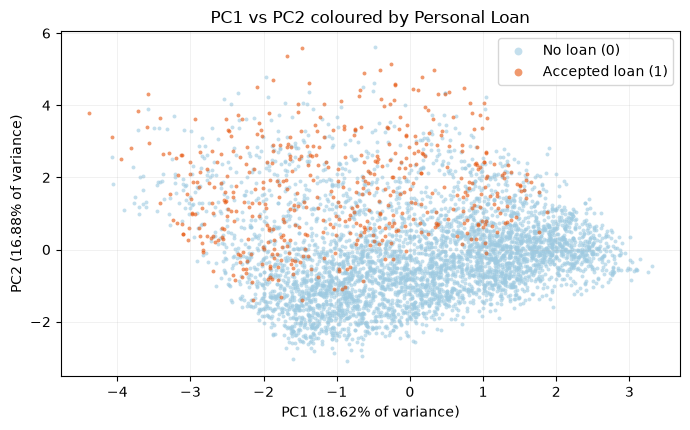

In [72]:
fig, ax = plt.subplots(figsize=(7, 4.4))
for label, colour, name in [(0, '#9ecae1', 'No loan (0)'), (1, '#e6550d', 'Accepted loan (1)')]:
    sub = df_pca[df_pca['Personal Loan'] == label]
    ax.scatter(sub['PC1'], sub['PC2'], s=8, c=colour, alpha=.6, linewidths=0, label=name)

evr = pca_viz.explained_variance_ratio_
ax.set_xlabel(f'PC1 ({evr[0]:.2%} of variance)')
ax.set_ylabel(f'PC2 ({evr[1]:.2%} of variance)')
ax.set_title('PC1 vs PC2 coloured by Personal Loan')
ax.legend(markerscale=2)
ax.grid(alpha=.25, linewidth=.5)
fig.tight_layout()
fig.savefig('pca_plot.png', dpi=200, bbox_inches='tight')
plt.show()


## Model comparison

| Model | Best settings | Dimensions | Accuracy | Recall 1 | F1 1 |
|---|---|---|---|---|---|
| Default KNN | k = 5 | 11 original predictors | 0.9608 | 0.6229 | 0.7525 |
| Optimized KNN | k = 1 | 11 original predictors | 0.9604 | 0.6938 | 0.7706 |
| Optimized PCA + KNN | components = 8, k = 1 | 8 components | 0.9568 | 0.6958 | 0.7552 |

**14. Which model should be selected?** The optimized KNN with k = 1 on the original predictors. It has
the best F1 and better recall than the default at the same
accuracy.

**15. Did PCA help?** No. PCA with 8 components matches recall but loses accuracy,
precision and F1.

**16. Most important metric if the bank wants to find as many potential loan customers as possible?**
Recall on class 1. Recall = TP / (TP + FN) is the share of true acceptors the model actually reaches.

## Predict a given customer

In [9]:
best_model = grid_knn.best_estimator_ 
customer = pd.DataFrame([{
    'Age': 40, 'Experience': 10, 'Income': 84, 'Family': 2, 'CCAvg': 2,
    'Education': 2, 'Mortgage': 0, 'Securities Account': 0,
    'CD Account': 0, 'Online': 1, 'CreditCard': 1,
}])[X.columns]

pred = best_model.predict(customer)[0]
proba = best_model.predict_proba(customer)[0]
print('Predicted Personal Loan :', pred)
print('Predicted probabilities  : P(0) =', proba[0], ', P(1) =', proba[1])

Predicted Personal Loan : 0
Predicted probabilities  : P(0) = 1.0 , P(1) = 0.0


### 17. Prediction

Personal Loan = 0 — this customer is predicted not to accept the loan. With k = 1 